# The other regulatory calculators: standardised credit RWA, BA-CVA, FRTB sensitivities and the output floor

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 04 of this topic (SA-CCR)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- look up a standardised credit-risk weight and read its paragraph, table and in-force date from the `RegulatoryParameter` that carries it;
- compute the reduced basic approach to CVA capital (BA-CVA) from an exposure at default, and show how correlation between counterparties lowers it;
- compute the GIRR delta charge of the sensitivities-based method under the three correlation scenarios, with and without the division of the risk weights by $\sqrt{2}$;
- compute the liquidity-horizon cascade of expected shortfall and the output floor with its phase-in and its cap;
- say which of these calculators are checked against a printed example and which only against invariants.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.regulatory import ba_cva, frtb, output_floor, standardised

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

Two committed documents feed this notebook.

- `data/derived/regulatory/calculators.json` (schema `contraste.regulatory/v1`, truth status `published-answer`): the 79-row grid of CRE20 risk weights, the phase-in of the output floor, the tables of BA-CVA risk weights and liquidity horizons, the invariant cases (BA-CVA, the sensitivities-based method, the liquidity cascade, the GIRR charge) and the two output-floor examples.
- `data/derived/C12/single-swap.json`: the 10-year payer swap of notebook 01, whose `ba_cva` and `girr` blocks hold a BA-CVA capital and a GIRR delta charge computed on its SA-CCR exposure and its sensitivities. The swap is synthetic, the curve is the US Treasury par curve of 2025-09-30.

What is verified against a printed example and what is not: the CRE20 weights and the output floor (RBC20.13) have printed values or complete tables; **BA-CVA has no verified official numeric example** (research addendum R8), so its tests rest on invariants and the document says so; the GIRR charge rests on the parameters transcribed from MAR21 and on the invariant that the undivided charge is $\sqrt{2}$ times the divided one.

The next cell loads both documents and prints their identity and the BA-CVA limit statement.

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root) and print their identity and limits
ROOT = Path("../../..").resolve()
doc = json.loads((ROOT / "data" / "derived" / "regulatory" / "calculators.json").read_text(encoding="utf-8"))
swap_doc = json.loads((ROOT / "data" / "derived" / "C12" / "single-swap.json").read_text(encoding="utf-8"))
swap = swap_doc["outputs"]

print("document:", doc["document_id"], "| baked by", doc["engine"]["version"], "| installed", rv.__version__)
print("rows of the CRE20 grid:", len(doc["cre20_grid"]), "| invariant cases:", len(doc["invariant_cases"]), "| phase-in years:", len(doc["output_floor_phase_in"]))
print("tables:", [t["id"] for t in doc["parameter_tables"]])
print("the C12 document marks its BA-CVA reading of M as unverified:", "UNVERIF" in swap["ba_cva"]["limit"]["en"])

document: regulatory-calculators-0.9.0 | baked by 0.9.0 | installed 0.9.0
rows of the CRE20 grid: 79 | invariant cases: 8 | phase-in years: 6
tables: ['cre52-72-table-2', 'mar50-16-table-1', 'mar33-12-table-2', 'mar33-4-table-1']
the C12 document marks its BA-CVA reading of M as unverified: True


## Method

### Step 1: standardised risk weights with their paragraph

Under the standardised approach to credit risk the risk-weighted assets of an exposure are $EAD \times RW$, with $RW$ read from a table by exposure class and rating bucket (CRE20). The difficulty is not the multiplication but the lookup: which table, which edge of an LTV band, whether the exposure is short term, which flag an unrated corporate carries. The engine's `lookup(exposure_class, key, **options)` dispatches to the right function and returns a `RegulatoryParameter`: the value with its paragraph, its table and the in-force date of the chapter version. A key outside the table is refused with a message that names the table, never answered with a placeholder. The next cell looks up a few weights, and then checks all 79 rows of the committed grid.

In [3]:
# Look up some weights with their paragraph, check the 79 rows of the committed grid, and see how a key outside the table is refused
sample = [("sovereign", "A+ to A-", {}), ("bank-scra", "A", {"short_term": True}), ("bank-scra", "A", {}), ("corporate", "BBB+ to BBB-", {}),
          ("corporate", "sme-unrated", {}), ("retail", "transactor", {}), ("residential-re", "0.7", {}), ("equity", "speculative-unlisted", {}),
          ("defaulted", "provision-below-20pct", {})]
for cls, key, options in sample:
    p = standardised.lookup(cls, key, **options)
    print(f"{cls:15s}{key:24s}{str(options):22s} RW = {p.value:5.2f} | {p.paragraph:10s} | {p.table} | {p.in_force}")

same = 0
for row in doc["cre20_grid"]:
    p = standardised.lookup(row["exposure_class"], row["key"], short_term=row["short_term"], cash_flow_dependent=row["cash_flow_dependent"],
                            counterparty_weight=row["counterparty_weight"])
    same += (p.value, p.paragraph, p.table, p.in_force) == (row["risk_weight"], row["paragraph"], row["table"], row["in_force_date"])
print("rows of the grid equal to the engine (weight, paragraph, table, date):", same, "of", len(doc["cre20_grid"]))

try:
    standardised.lookup("corporate", "AA")
except ValueError as err:
    print("a key outside the table is refused with a ValueError that names the table CRE20 Table 10:", "CRE20 Table 10" in str(err))

book = [("corporate A", "corporate", "A+ to A-", 100.0), ("unrated SME", "corporate", "sme-unrated", 40.0),
        ("mortgage, LTV 70%", "residential-re", "0.7", 80.0), ("retail transactor", "retail", "transactor", 20.0)]
total = 0.0
for name, cls, key, ead in book:
    rw = standardised.lookup(cls, key).value
    total += ead * rw
    print(f"{name:34s} EAD {ead:6.1f} x RW {rw:4.2f} = RWA {ead * rw:7.2f}")
print("total RWA of the small book:", total)

sovereign      A+ to A-                {}                     RW =  0.20 | CRE20.7    | CRE20 Table 1 | 2023-01-01
bank-scra      A                       {'short_term': True}   RW =  0.20 | CRE20.21   | CRE20 Table 7 | 2023-01-01
bank-scra      A                       {}                     RW =  0.40 | CRE20.21   | CRE20 Table 7 | 2023-01-01
corporate      BBB+ to BBB-            {}                     RW =  0.75 | CRE20.43   | CRE20 Table 10 | 2023-01-01
corporate      sme-unrated             {}                     RW =  0.85 | CRE20.47   | CRE20.47 | 2023-01-01
retail         transactor              {}                     RW =  0.45 | CRE20.68   | CRE20.68 | 2023-01-01
residential-re 0.7                     {}                     RW =  0.30 | CRE20.82   | CRE20 Table 11 | 2023-01-01
equity         speculative-unlisted    {}                     RW =  4.00 | CRE20.57   | CRE20.57 to CRE20.60 | 2023-01-01
defaulted      provision-below-20pct   {}                     RW =  1.50 | CRE20.

### Step 2: the basic approach to CVA capital

BA-CVA (MAR50.14 to MAR50.16) turns the exposure at default of each counterparty into a CVA capital without simulation. For counterparty $c$ with netting sets $NS$, effective maturity $M$ and exposure at default $EAD$ (the SA-CCR one for a bank without an internal model):

$$SCVA_c = \frac{1}{\alpha}\,RW_c \sum_{NS} M_{NS}\,EAD_{NS}\,DF_{NS}, \quad DF = \frac{1 - e^{-0.05 M}}{0.05\,M}, \quad \alpha = 1.4$$

$$K_{reduced} = \sqrt{\Big(\rho \sum_c SCVA_c\Big)^2 + (1 - \rho^2) \sum_c SCVA_c^2}, \quad \rho = 50\%, \qquad \text{Capital} = DS \times K_{reduced},\ DS = 0.65$$

$RW_c$ comes from MAR50.16 Table 1 by sector and by investment grade or not. The next cell recomputes the capital of the single swap against one investment-grade financial counterparty from its SA-CCR exposure (notebook 04), and compares with the committed block. The maturity $M$ is the notional-weighted average maturity of the netting set; the document marks that reading of the paragraph as UNVERIFIED, and so do we. Then it shows how $\rho$ works with two equal counterparties, and the two invariants of the document.

In [4]:
# BA-CVA capital of the single swap from its SA-CCR exposure, the effect of rho on two counterparties, and the two invariants of the document
cp = swap["ba_cva"]["counterparties"][0]
rw = ba_cva.sector_risk_weight(cp["sector"], True)
df = ba_cva.discount_factor(cp["m_years"], imm_bank=False)
scva = ba_cva.scva(rw.value, [(cp["m_years"], cp["ead"]["amount"])], imm_bank=False)
k_red = ba_cva.k_reduced([scva])
capital = ba_cva.capital(k_red)
print("sector and class:", cp["sector"], cp["rating_class"], "| RW =", rw.value, "|", rw.paragraph, rw.table)
print("EAD (SA-CCR, committed sa_ccr.ead):", round(cp["ead"]["amount"], 2), "| M =", cp["m_years"], "| DF =", round(df, 6))
print("SCVA:", round(scva, 2), "| K_reduced:", round(k_red, 2), "| capital = 0.65 K:", round(capital, 2))
print("gap to the committed SCVA and capital:", abs(scva - cp["scva"]), abs(capital - swap["ba_cva"]["capital"]["amount"]))
print("capital as a share of the exposure at default:", round(capital / cp["ead"]["amount"], 4))

for rho in (0.0, 0.5, 1.0):
    print(f"rho = {rho:3.1f} | K_reduced of two counterparties with SCVA 100:", round(ba_cva.k_reduced([100.0, 100.0], rho), 4))
for case in doc["invariant_cases"]:
    if case["calculator"] == "ba-cva":
        print(case["id"], "| holds in the document:", case["holds"], "|", case["statement"]["en"])
print("K_full with no hedges, beta 0.25, K_reduced 30:", ba_cva.k_full(30.0, 0.0, 0.25), "| materiality threshold applies at EUR 100 billion:", ba_cva.materiality_threshold_applies(1e11))

sector and class: financials investment-grade | RW = 0.05 | MAR50.16 MAR50.16 Table 1
EAD (SA-CCR, committed sa_ccr.ead): 528459.73 | M = 10.0 | DF = 0.786939
SCVA: 148523.36 | K_reduced: 148523.36 | capital = 0.65 K: 96540.18
gap to the committed SCVA and capital: 0.0 0.0
capital as a share of the exposure at default: 0.1827
rho = 0.0 | K_reduced of two counterparties with SCVA 100: 141.4214
rho = 0.5 | K_reduced of two counterparties with SCVA 100: 158.1139
rho = 1.0 | K_reduced of two counterparties with SCVA 100: 200.0
ba-cva-rho-one | holds in the document: True | With rho = 1 the reduced capital base K_reduced equals the sum of the SCVA.
ba-cva-hedges-floor | holds in the document: True | K_full = beta K_reduced + (1 - beta) K_hedged is at least beta K_reduced.
K_full with no hedges, beta 0.25, K_reduced 30: 7.5 | materiality threshold applies at EUR 100 billion: True


### Step 3: the sensitivities-based method, GIRR delta

For interest-rate risk in the trading book, the sensitivities-based method (MAR21) weights the sensitivity $s_k$ of the position to each of the ten tenors by a risk weight, $WS_k = RW_k\,s_k$, and aggregates inside a currency bucket with the correlations between tenors:

$$K_b = \sqrt{\max\Big(0,\ \sum_k WS_k^2 + \sum_{k \ne l} \rho_{kl}\,WS_k\,WS_l\Big)}$$

The sensitivity is $s_k = (V(r + 0.0001) - V(r))/0.0001$, the change of value for a one basis point shift **divided by 0.0001**, not the PV01. The capital is the maximum of $K_b$ over three correlation scenarios (MAR21.6): medium is $\rho$, high is $\min(1.25\rho, 1)$ and low is $\max(2\rho - 1, 0.75\rho)$. For a specified currency such as USD the bank may divide the risk weights by $\sqrt{2}$ (MAR21.44); the document treats that as a named parameter with the label `convention` and writes the undivided charge beside the divided one. The next cell reads the ten sensitivities of the single swap, computes the charge both ways, and compares with the committed block.

In [5]:
# GIRR delta charge of the single swap with and without the division by sqrt(2), the three scenarios, against the committed block
div, und = frtb.girr_parameters(True), frtb.girr_parameters(False)
s = np.array(swap["girr"]["sensitivities"])
head, beside = frtb.girr_delta_charge(s, div.tenors, div), frtb.girr_delta_charge(s, und.tenors, und)

print(f"{'tenor':>7s}{'s_k':>16s}{'RW %':>8s}{'RW/sqrt2 %':>12s}{'WS':>14s}")
for t, sk, a1, a2, ws in zip(div.tenors, s, und.risk_weights, div.risk_weights, head.weighted):
    print(f"{t:7.2f}{sk:16.1f}{a1 * 100:8.2f}{a2 * 100:12.3f}{ws:14.1f}")
print("K_b low / medium / high:", [round(k, 2) for k in head.k_by_scenario], "| charge = maximum:", round(head.charge, 2))
print("committed charge and undivided charge:", round(swap["girr"]["delta_charge"]["amount"], 2), round(swap["girr"]["delta_charge_undivided"]["amount"], 2))
print("gap of the divided charge to the committed one:", abs(head.charge - swap["girr"]["delta_charge"]["amount"]), "| undivided / divided:", round(beside.charge / head.charge, 6), "| sqrt(2) =", round(frtb.SQRT2, 6))
print("share of the charge from the 10-year tenor:", round(abs(head.weighted[6]) / head.charge, 3))

  tenor             s_k    RW %  RW/sqrt2 %            WS
   0.25             0.0    1.70       1.202           0.0
   0.50        103024.5    1.70       1.202        1238.4
   1.00        351675.5    1.60       1.131        3978.8
   2.00        780319.5    1.30       0.919        7173.0
   3.00       1854805.6    1.20       0.849       15738.5
   5.00       6905676.2    1.10       0.778       53713.6
  10.00      72734182.1    1.10       0.778      565739.2
  15.00             0.0    1.10       0.778           0.0
  20.00             0.0    1.10       0.778           0.0
  30.00             0.0    1.10       0.778           0.0
K_b low / medium / high: [639060.91, 643092.67, 647099.31] | charge = maximum: 647099.31
committed charge and undivided charge: 647099.31 915136.62
gap of the divided charge to the committed one: 0.0 | undivided / divided: 1.414214 | sqrt(2) = 1.414214
share of the charge from the 10-year tenor: 0.874


Two cases of the document show the aggregation rule at work. In the first, two buckets of the same sign are aggregated across buckets with $\gamma = 0.5$ under the three scenarios and the SBM result is the largest. In the second, two buckets of opposite sign and $\gamma = 0.8$ make the radicand negative under the medium and high scenarios, and MAR21.4(5)(b) replaces $S_b$ by $\max(\min(\sum WS, K_b), -K_b)$; the engine reports whether the fallback was used. The liquidity-horizon cascade of expected shortfall (MAR33.4) adds the shortfall of the factors with longer horizons:

$$ES = \sqrt{ES_T(P)^2 + \sum_{j \ge 2} \Big(ES_T(P, j)\sqrt{\tfrac{LH_j - LH_{j-1}}{T}}\Big)^2}$$

The next cell runs the two aggregation cases and the cascade of the document from their inputs.

In [6]:
# Run the two SBM aggregation cases and the liquidity cascade of the document from their inputs and compare with their committed outputs
cases = {c["id"]: c for c in doc["invariant_cases"]}
print("scenario correlations for rho = 0.5 (low, medium, high):", [float(frtb.scenario_correlation(np.array(0.5), sc)) for sc in frtb.SCENARIOS])
for ident in ("sbm-bucket-and-cross-bucket-aggregation", "sbm-cross-bucket-fallback"):
    ins = {i["name"]: i["value"] for i in cases[ident]["inputs"]}
    outs = {o["name"]: o["value"] for o in cases[ident]["outputs"]}
    ws = [np.array(ins[k]) for k in sorted(ins) if k.startswith("ws_")]
    rho = [np.array(ins[f"rho_{b + 1}"]).reshape(len(w), len(w)) for b, w in enumerate(ws)]
    gamma = np.full((2, 2), ins["gamma"])
    np.fill_diagonal(gamma, 1.0)
    cross = {}
    print(ident)
    for sc in frtb.SCENARIOS:
        k_b = np.array([frtb.bucket_charge(w, r_, sc) for w, r_ in zip(ws, rho)])
        detail = frtb.cross_bucket_charge_detail(k_b, np.array([w.sum() for w in ws]), gamma, sc)
        cross[sc] = detail.charge
        print(f"  {sc:6s} K_b = {np.round(k_b, 4)} | cross-bucket {detail.charge:9.4f} | fallback used: {detail.fallback_used} | committed {outs['cross_bucket_' + sc]:.4f}")
    zero = {sc: 0.0 for sc in frtb.SCENARIOS}
    sbm = frtb.sbm_capital(cross, zero, zero)
    print("  SBM:", round(sbm.capital, 6), "scenario", sbm.scenario, "| committed", round(outs["sbm_charge"], 6))

ins = {i["name"]: i["value"] for i in cases["cascade-two-horizons"]["inputs"]}
es = frtb.liquidity_cascade_es(ins["es_t_p"], {int(ins["lh_2"]): ins["es_t_p_2"]}, int(ins["t"]))
print("cascade ES:", round(es, 6), "| committed", round(cases["cascade-two-horizons"]["outputs"][0]["value"], 6), "| at least the base ES:", es >= ins["es_t_p"])
print("cascade with every horizon equal to 10 returns the base ES:", frtb.liquidity_cascade_es(10.0, {}, 10))

scenario correlations for rho = 0.5 (low, medium, high): [0.375, 0.5, 0.625]
sbm-bucket-and-cross-bucket-aggregation
  low    K_b = [11.0454  6.7268] | cross-bucket   15.4677 | fallback used: False | committed 15.4677
  medium K_b = [10.583  7.   ] | cross-bucket   16.0312 | fallback used: False | committed 16.0312
  high   K_b = [10.0995  7.2629] | cross-bucket   16.5756 | fallback used: False | committed 16.5756
  SBM: 16.575584 scenario high | committed 16.575584
sbm-cross-bucket-fallback
  low    K_b = [16.5831 16.5831] | cross-bucket    8.3666 | fallback used: False | committed 8.3666
  medium K_b = [17.3205 17.3205] | cross-bucket   10.9545 | fallback used: True | committed 10.9545
  high   K_b = [18.0278 18.0278] | cross-bucket    0.0000 | fallback used: True | committed 0.0000
  SBM: 10.954451 scenario medium | committed 10.954451
cascade ES: 11.661904 | committed 11.661904 | at least the base ES: True
cascade with every horizon equal to 10 returns the base ES: 10.0


### Step 4: the output floor

The output floor limits how far internal models can lower the capital: the risk-weighted assets are

$$RWA = \max\big(RWA_{nominated},\ f_t \times RWA_{SA\text{-}only}\big)$$

where $RWA_{SA\text{-}only}$ is computed with the standardised approaches only (RBC20.11 to RBC20.12) and $f_t$ rises each year from 50% in 2023 to 72.5% from 2028 (RBC90.1 Table 1). During the phase-in a national cap can limit the increase caused by the floor to 25% of the pre-floor RWA (RBC90.2). The engine's `phase_in_factor` and `floored_rwa` are two small functions; the value of the check is in the documented example (RBC20.13): nominated RWA 76, standardised-only 140, factor 72.5%, giving 101.5, and 95 with the cap. The next cell evaluates the example, the phase-in year by year and the cap, and draws the floored RWA by year.

rbc20-13-output-floor          result 101.500 | printed 101.5 | committed 101.5
rbc20-13-output-floor-capped   result  95.000 | printed 95 | committed 95.0
  year    f_t     floored RWA    with 25% cap  binding
  2023  0.500           76.00           76.00  False
  2024  0.550           77.00           77.00  True
  2025  0.600           84.00           84.00  True
  2026  0.650           91.00           91.00  True
  2027  0.700           98.00           95.00  True
  2028  0.725          101.50           95.00  True
first year in which the floor binds: 2024
a year before 2023 is refused with a ValueError that names RBC90.1: True


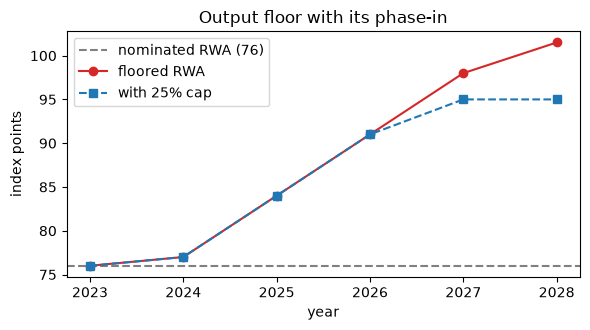

In [7]:
# Evaluate the documented example, the phase-in year by year with the cap, and compare with the committed phase-in table
floor_examples = {e["id"]: e for e in doc["official_examples"] if e["calculator"] == "output-floor"}
for ident, e in floor_examples.items():
    ins = {i["name"]: i["value"] for i in e["inputs"]}
    value = output_floor.floored_rwa(ins["rwa_nominated"], ins["rwa_sa_only"], ins["floor_factor"], ins.get("cap_share"))
    print(f"{ident:30s} result {value:7.3f} | printed {e['published'][0]['value']} | committed {e['outputs'][0]['value']}")

nominated, sa_only = 76.0, 140.0
years = list(range(2023, 2029))
rows = []
for year in years:
    f = output_floor.phase_in_factor(year)
    rows.append((year, f.value, output_floor.floored_rwa(nominated, sa_only, f.value), output_floor.floored_rwa(nominated, sa_only, f.value, 0.25)))
    committed = next(r for r in doc["output_floor_phase_in"] if r["year"] == year)
    assert (f.value, f.paragraph, f.table) == (committed["factor"], committed["paragraph"], committed["table"])
print(f"{'year':>6s}{'f_t':>7s}{'floored RWA':>16s}{'with 25% cap':>16s}  binding")
for year, f, floored, capped in rows:
    print(f"{year:6d}{f:7.3f}{floored:16.2f}{capped:16.2f}  {floored > nominated}")
print("first year in which the floor binds:", next(y for y, _, fl, _c in rows if fl > nominated))
try:
    output_floor.phase_in_factor(2022)
except ValueError as err:
    print("a year before 2023 is refused with a ValueError that names RBC90.1:", "RBC90.1" in str(err))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.axhline(nominated, color="grey", ls="--", label="nominated RWA (76)")
ax.plot(years, [r_[2] for r_ in rows], "o-", color="tab:red", label="floored RWA")
ax.plot(years, [r_[3] for r_ in rows], "s--", color="tab:blue", label="with 25% cap")
ax.set_xlabel("year")
ax.set_ylabel("index points")
ax.set_title("Output floor with its phase-in")
ax.legend()
fig.tight_layout()
plt.show()

## Results

- **Risk weights.** A sovereign rated A+ to A- weighs 20%, a bank of SCRA grade A 40% (20% if short term), a corporate rated BBB 75%, an unrated SME 85%, a transactor 45%, a mortgage at an LTV of 70% 30%, speculative unlisted equity 400%, and a defaulted exposure with a provision below 20% 150%. Every one comes with its paragraph, table and in-force date. All 79 rows of the committed grid equal the engine's lookup in weight, paragraph, table and date, and a key outside the table (a corporate rating "AA") is refused with the name of the table. The small book of four exposures has RWA 117.0.
- **BA-CVA.** For the single swap, with an exposure at default of 528,459.73 USD from SA-CCR, a financial counterparty of investment grade (risk weight 5%) and a 10-year maturity (discount factor 0.7869), SCVA is 148,523.36 and the capital is $0.65 \times K_{reduced} = 96,540.18$ USD, 18.3% of the exposure at default; both equal the committed block. With two counterparties of SCVA 100 each, $K_{reduced}$ is 141.42 at $\rho=0$, 158.11 at $\rho=0.5$ and 200 at $\rho=1$, the plain sum: the less the counterparties move together, the lower the capital, by 21% at $\rho=0.5$ and 29% at $\rho=0$ against the sum. The two invariants hold, and $K_{full}$ with no hedges is $\beta K_{reduced} = 7.5$. There is no verified official example, so these are checks of structure, not of a published number.
- **GIRR delta.** The 10-year tenor carries 87.4% of the charge, because the swap is long and its sensitivity concentrates there. The medium scenario gives $K_b$ = 643,092.67, the low one 639,060.91 and the high one 647,099.31, which is the charge (equal to the committed one). Dividing the risk weights by $\sqrt{2}$ gives 647,099.31 and not dividing gives 915,136.62, a ratio of 1.414214: the charge is homogeneous of degree one in the weights, so the division is a pure scale choice that a bank makes at its discretion, and the document shows both.
- **Aggregation.** In the two-bucket case the high correlation scenario gives the largest charge, 16.5756. In the case of opposite signs with $\gamma=0.8$ the low scenario applies the plain formula (8.3666) while the medium and the high scenarios fall back to $\max(\min(\sum WS, K_b), -K_b)$, and the engine says so; the charge is the medium value, 10.9545. The liquidity cascade with a second horizon gives 11.6619 from a base of 10, and it returns the base when every horizon is 10.
- **Output floor.** The example gives 101.5, and 95 with the cap, as printed. With nominated RWA 76 and standardised RWA 140 the floor first binds in 2024 (77 against 76), grows to 101.5 in 2028, and the 25% cap holds the result at 95 from 2027.

What this notebook does not show: the standardised risk weights are the transcribed tables of the engine, and mapping a rating to a bucket (CRE21) is the caller's; the full BA-CVA hedge terms, SA-CVA, vega, curvature, the other risk classes of the sensitivities-based method, the default risk charge and the residual risk add-on are not implemented.

## Summary

- A standardised risk weight is a `RegulatoryParameter`: a value with its paragraph, table and in-force date, found by `lookup`, and refused with the name of the table when the key is not in it.
- BA-CVA capital is $0.65\sqrt{(\rho\sum SCVA)^2 + (1-\rho^2)\sum SCVA^2}$ with $SCVA$ from the exposure at default; it has no verified official example, and the notebook says what it rests on.
- The GIRR delta charge is the maximum over three correlation scenarios of the aggregation of $RW_k s_k$; dividing the weights by $\sqrt{2}$ scales the charge by exactly $1/\sqrt{2}$.
- The output floor is $\max(\text{nominated}, f_t \times \text{standardised})$ with $f_t$ from 50% to 72.5%; the documented example gives 101.5 and 95 with the cap.

**What to try next.** Change the sector of the counterparty to `technology-telecoms` or its credit quality to high yield and watch the BA-CVA capital; use the `lookup` of a commercial real-estate exposure with and without a counterparty weight. Then continue with notebook 06.

## References

- BCBS, Basel Framework, CRE20 Standardised approach: individual exposures (in force 2023-01-01, published 2025-06-10). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/20/inforce/2023-01-01/published/2025-06-10
- BCBS, Basel Framework, MAR50 CVA risk framework (in force 2023-01-01, published 2020-07-08). https://www.bis.org/committees/bcbs/basel-framework/standard/mar/50/inforce/2023-01-01/published/2020-07-08
- BCBS, Basel Framework, MAR21 Standardised approach: sensitivities-based method (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/mar/21/inforce/2023-01-01/published/2026-03-23
- BCBS, Basel Framework, RBC20 Calculation of minimum risk-based capital requirements (in force 2023-01-01, published 2020-11-26). https://www.bis.org/committees/bcbs/basel-framework/standard/rbc/20/inforce/2023-01-01/published/2020-11-26
- BCBS, Basel Framework, RBC90 Transitional arrangements and the output floor phase-in (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/rbc/90/inforce/2023-01-01/published/2020-03-27
- BCBS, Basel Framework, CRE52 Standardised approach to counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/52/inforce/2023-01-01/published/2020-06-05